In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
print(os.getcwd())
print(os.getcwd())
print(os.path.exists("datos/credit_risk_dataset.csv"))


/workspaces/Proyecto-Credit-Risk-Dataset/cuadernos
/workspaces/Proyecto-Credit-Risk-Dataset/cuadernos
False


In [2]:
df = pd.read_csv(os.path.join("..", "datos", "credit_risk_dataset.csv"))

In [8]:
# %% [markdown]
# ## 2. Manejo de datos faltantes  (Integrante B)
df_limpio = df.copy()

faltantes = pd.DataFrame({
    "faltantes": df_limpio.isna().sum(),
    "porcentaje": (df_limpio.isna().mean() * 100).round(2),
})
faltantes = faltantes[faltantes["faltantes"] > 0]
print(faltantes)

cols_nulos = faltantes.index.tolist()
print("\nFilas con al menos un faltante:", df_limpio.isna().any(axis=1).sum())
print("Filas con ambos faltantes:", df_limpio[cols_nulos].isna().all(axis=1).sum())

                   faltantes  porcentaje
person_emp_length        895        2.75
loan_int_rate           3116        9.56

Filas con al menos un faltante: 3943
Filas con ambos faltantes: 68


In [4]:
edades_raras = (df["person_age"] > 100).sum()
antig_rara = (df["person_emp_length"] > 60).sum()
print(f"Personas con edad mayor a 100 años: {edades_raras}")
print(f"Personas con más de 60 años de antigüedad laboral: {antig_rara}")
 
df2 = df.copy()
df2.loc[df2["person_age"] > 100, "person_age"] = np.nan
df2.loc[df2["person_emp_length"] > 60, "person_emp_length"] = np.nan
print("\nEstos valores imposibles se convirtieron en datos faltantes (NaN).")

Personas con edad mayor a 100 años: 5
Personas con más de 60 años de antigüedad laboral: 2

Estos valores imposibles se convirtieron en datos faltantes (NaN).


In [9]:
edades_raras = (df_limpio["person_age"] > 100).sum()
antig_rara = (df_limpio["person_emp_length"] > 60).sum()
print(f"Personas con edad mayor a 100 años: {edades_raras}")
print(f"Personas con más de 60 años de antigüedad laboral: {antig_rara}")

df_limpio.loc[df_limpio["person_age"] > 100, "person_age"] = np.nan
df_limpio.loc[df_limpio["person_emp_length"] > 60, "person_emp_length"] = np.nan
print("\nEstos valores imposibles se convirtieron en datos faltantes (NaN) en df_limpio.")

Personas con edad mayor a 100 años: 5
Personas con más de 60 años de antigüedad laboral: 2

Estos valores imposibles se convirtieron en datos faltantes (NaN) en df_limpio.


In [10]:
df_limpio["loan_int_rate"] = df_limpio["loan_int_rate"].fillna(
    df_limpio.groupby("loan_grade")["loan_int_rate"].transform("median"))

df_limpio["person_emp_length"] = df_limpio["person_emp_length"].fillna(
    df_limpio.groupby("person_home_ownership")["person_emp_length"].transform("median"))

df_limpio["person_age"] = df_limpio["person_age"].fillna(df_limpio["person_age"].median())

# %% Resultado después de imputar
print("Datos faltantes por columna después de imputar:")
print(df_limpio.isna().sum())
print("\nTotal de datos faltantes:", df_limpio.isna().sum().sum())

print("\nPrimeras 5 filas del dataframe limpio:")
print(df_limpio.head())

# Filas que originalmente tenían un dato faltante, ya imputadas
filas_imputadas = df.index[df["loan_int_rate"].isna() | df["person_emp_length"].isna()]
comparacion = pd.DataFrame({
    "tasa_original": df.loc[filas_imputadas, "loan_int_rate"],
    "tasa_imputada": df_limpio.loc[filas_imputadas, "loan_int_rate"],
    "antig_original": df.loc[filas_imputadas, "person_emp_length"],
    "antig_imputada": df_limpio.loc[filas_imputadas, "person_emp_length"],
    "calificacion": df_limpio.loc[filas_imputadas, "loan_grade"],
    "vivienda": df_limpio.loc[filas_imputadas, "person_home_ownership"],
})


print("\nDimensiones del dataframe limpio:", df_limpio.shape)

Datos faltantes por columna después de imputar:
person_age                    0
person_income                 0
person_home_ownership         0
person_emp_length             0
loan_intent                   0
loan_grade                    0
loan_amnt                     0
loan_int_rate                 0
loan_status                   0
loan_percent_income           0
cb_person_default_on_file     0
cb_person_cred_hist_length    0
dtype: int64

Total de datos faltantes: 0

Primeras 5 filas del dataframe limpio:
   person_age  person_income person_home_ownership  person_emp_length  \
0        22.0          59000                  RENT                3.0   
1        21.0           9600                   OWN                5.0   
2        25.0           9600              MORTGAGE                1.0   
3        23.0          65500                  RENT                4.0   
4        24.0          54400                  RENT                8.0   

  loan_intent loan_grade  loan_amnt  loan_int_r

                   Faltantes  Porcentaje (%)
person_emp_length        895            2.75
loan_int_rate           3116            9.56


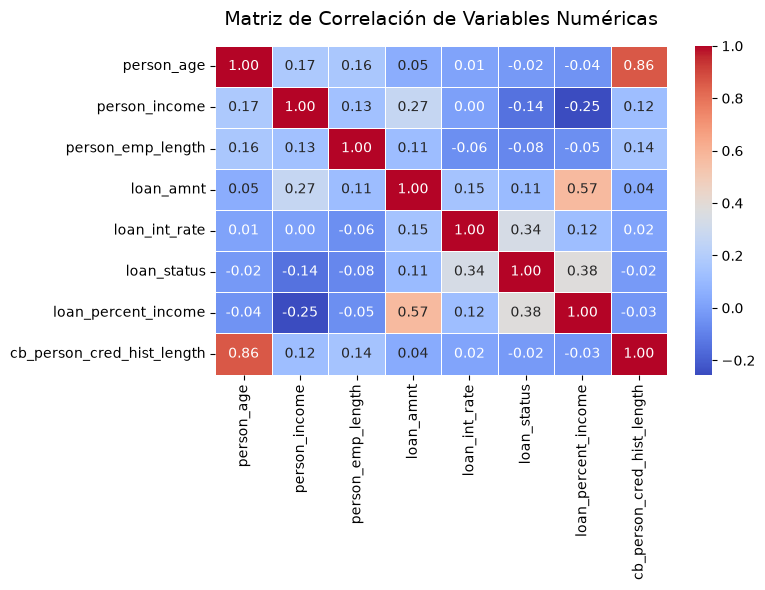

In [7]:
corr_matrix = df.select_dtypes(include=['number']).corr()
nulos_df = pd.DataFrame(
    {
        'Faltantes': df.isnull().sum(),
        'Porcentaje (%)': (df.isnull().mean() * 100).round(2),
    }
)
print(nulos_df[nulos_df['Faltantes'] > 0])

plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5
)
plt.title('Matriz de Correlación de Variables Numéricas', fontsize=14, pad=15)
plt.tight_layout()
plt.show()


In [ ]:
# %% [markdown]
# ## 4. Valores inconsistentes y duplicados
# %% Valores inconsistentes en texto
cols_texto = df_limpio.select_dtypes(include=["object", "string"]).columns.tolist()
print("Columnas de texto:", cols_texto)

# Categorías antes de limpiar
for col in cols_texto:
    print(f"\n{col}: {df_limpio[col].nunique()} categorías")
    print(df_limpio[col].value_counts(dropna=False))

Columnas de texto: ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']

person_home_ownership: 4 categorías
person_home_ownership
RENT        16446
MORTGAGE    13444
OWN          2584
OTHER         107
Name: count, dtype: int64

loan_intent: 6 categorías
loan_intent
EDUCATION            6453
MEDICAL              6071
VENTURE              5719
PERSONAL             5521
DEBTCONSOLIDATION    5212
HOMEIMPROVEMENT      3605
Name: count, dtype: int64

loan_grade: 7 categorías
loan_grade
A    10777
B    10451
C     6458
D     3626
E      964
F      241
G       64
Name: count, dtype: int64

cb_person_default_on_file: 2 categorías
cb_person_default_on_file
N    26836
Y     5745
Name: count, dtype: int64
Valores modificados por columna al estandarizar:
person_home_ownership        0
loan_intent                  0
loan_grade                   0
cb_person_default_on_file    0
dtype: int64


In [13]:
# %% 4.2 Estandarizar texto (se guarda en df_limpio)
antes = df_limpio[cols_texto].copy()

for col in cols_texto:
    df_limpio[col] = df_limpio[col].str.strip().str.upper()

cambios = (antes != df_limpio[cols_texto]).sum()
print("Valores modificados por columna al estandarizar:")
print(cambios)

Valores modificados por columna al estandarizar:
person_home_ownership        0
loan_intent                  0
loan_grade                   0
cb_person_default_on_file    0
dtype: int64
